# optical_lattices: usage

A quick tour of the package, from lab parameters to a tight-binding model, for the tunable lattice

$$V(x, y) = -V_1 \cos^2\!\big(k(x+y) + \tfrac{\phi}{2}\big) - V_2 \cos^2(kx)\cos^2(ky),$$

with a one-dimensional lattice $L_1$ along $x=y$, formed by a counter-propagating beam (depth $V_1$), on top of a square lattice $L_2$ formed by a bowtie configuration (depth $V_2$), and their relative phase $\phi$.
$\phi = \pi$ gives the brick-wall lattice used below, $\phi = 0$ the triangular lattice.

**Units.** $\hbar = 1$, $k = \pi$ and $m = \pi^2/2$, so that lengths are in the lattice constant $a = \pi/k = 1$ and energies in recoil units $E_r = \hbar^2k^2/2m = 1$.

Every module takes the same `Config`:

| Module | What it does |
|---|---|
| `Config` | lattice depths and phase, numerical parameters |
| `Potential` | the potential $V(x, y)$ in real space |
| `Energy` | band structure from a plane-wave expansion |
| `Wannier` | maximally localized Wannier functions (via Wannier90), tight-binding Hamiltonian, Hubbard $U$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from optical_lattices import Config, Potential, Energy, Wannier

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11})

## 1. Config

- `V1`, `V2`: lattice depths in $E_r$. $V_2$ is the depth of the resulting square lattice, not of the generating laser beam (which is $V_2/4$).
- `phi`: relative phase between $L_1$ and $L_2$.
- `k`: lattice wavevector $\pi/a$, which sets the length and energy scales. Leave it at the default $\pi$ ($a = 1$).
- `L_max`: plane-wave cutoff, which sets the accuracy of the band calculation (default 10).
- `num_q`: number of quasimomentum points per direction for the wannierization (default 20, sufficient for well-converged Wannier functions).
- `num_wannier`: number of Wannier functions, i.e. of bands to wannierize (default 2, for the double wells of the brick-wall lattice).

The atomic parameters for the Hubbard $U$ have defaults for $^{87}$Rb; see `help(Config)` for the full list.

In [2]:
config = Config(V1=15, V2=11, phi=np.pi)
config

Config(V1=15, V2=11, phi=3.141592653589793, k=3.141592653589793, w_z=1, L_max=10, num_q=20, num_wannier=2, wannier90_executor='Path', wannier90_dir=None, a_s_bohr=95.0, lattice_constant_nm=752.0)

## 2. Potential

For $r = V_1/V_2 \geq 1/2$ each unit cell holds a double well, with minima at $\pm(p, p)$, $p = \arccos\!\big(1/(4r-1)\big)/2k$.
We label them $A = (-p, -p)$ and $B = (p, p)$.

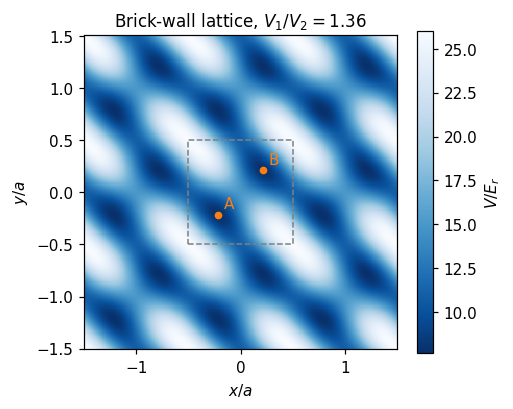

In [3]:
potential = Potential(config)

r = config.V1 / config.V2
p = np.arccos(1 / (4 * r - 1)) / (2 * config.k)
wells = {"B": (p, p), "A": (-p, -p)}

x = y = np.linspace(-1.5, 1.5, 301)
X, Y = np.meshgrid(x, y)
V = potential.potential(X, Y)

fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = ax.pcolormesh(X, Y, V, cmap="Blues_r", rasterized=True)
fig.colorbar(im, label=r"$V/E_r$")
ax.plot([-0.5, 0.5, 0.5, -0.5, -0.5], [-0.5, -0.5, 0.5, 0.5, -0.5], "--", color="grey", lw=1)
for name, (wx, wy) in wells.items():
    ax.plot(wx, wy, "o", color="C1", ms=4)
    ax.annotate(name, (wx, wy), xytext=(4, 4), textcoords="offset points", color="C1")
ax.set(xlabel="$x/a$", ylabel="$y/a$", aspect="equal", title=f"Brick-wall lattice, $V_1/V_2 = {r:.2f}$")
plt.show()

## 3. Energy bands

`Energy.get_energies(qx, qy, num_bands)` diagonalizes the plane-wave Hamiltonian at one quasimomentum.
Here along the path $\Gamma \to X \to M \to \Gamma \to M' \to X' \to \Gamma$ of the square Brillouin zone,
with $X = (\pi/a, 0)$, $M = (\pi/a, \pi/a)$, $M' = (-\pi/a, \pi/a)$, $X' = (-\pi/a, 0)$.
$M'$ is the same point as $M$, but the second loop is needed: $L_1$ breaks the fourfold symmetry, so the anti-diagonal $\Gamma \to M'$ is not equivalent to the diagonal $\Gamma \to M$.

The two lowest bands (one per well) are separated from the rest, which is what makes a two-band tight-binding model possible.
They touch on the anti-diagonal $\Gamma \to M'$: a Dirac point, as in graphene.

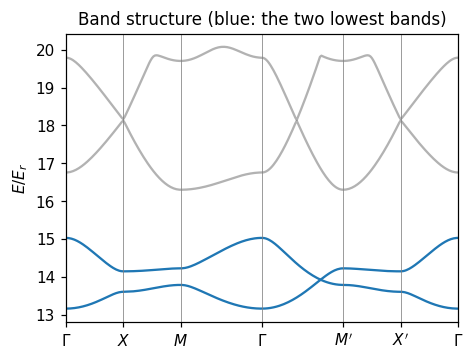

In [4]:
energy = Energy(config)

k = config.k
corners = {r"$\Gamma$": (0, 0), "$X$": (k, 0), "$M$": (k, k), "$M'$": (-k, k), "$X'$": (-k, 0)}
path_labels = [r"$\Gamma$", "$X$", "$M$", r"$\Gamma$", "$M'$", "$X'$", r"$\Gamma$"]
points = [np.array(corners[c]) for c in path_labels]

qs, dist, ticks = [], [], [0.0]
for start, end in zip(points[:-1], points[1:]):
    n = int(40 * np.linalg.norm(end - start) / k)
    for t in np.linspace(0, 1, n, endpoint=False):
        qs.append(start + t * (end - start))
    ticks.append(ticks[-1] + np.linalg.norm(end - start))
qs.append(points[-1])
qs = np.array(qs)
dist = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(qs, axis=0), axis=1))])

bands = np.array([energy.get_energies(qx, qy, num_bands=4) for qx, qy in qs])

fig, ax = plt.subplots(figsize=(4.6, 3.4))
ax.plot(dist, bands[:, :2], color="C0")
ax.plot(dist, bands[:, 2:], color="grey", alpha=0.6)
ax.set_xticks(ticks, path_labels)
for t in ticks[1:-1]:
    ax.axvline(t, color="grey", lw=0.5)
ax.set(xlim=(0, ticks[-1]), ylabel=r"$E/E_r$", title="Band structure (blue: the two lowest bands)")
plt.show()

The same two bands over the whole Brillouin zone, with the two Dirac cones on the anti-diagonal:

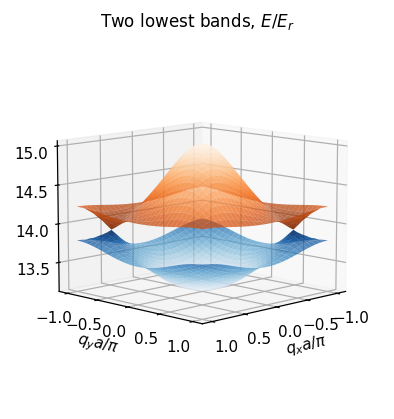

In [5]:
q = np.linspace(-k, k, 30)
QX, QY = np.meshgrid(q, q)
E = np.array([[energy.get_energies(qx, qy, num_bands=2) for qx in q] for qy in q])

fig = plt.figure(figsize=(5.4, 4.4))
ax = fig.add_subplot(projection="3d")
style = dict(alpha=0.7, antialiased=True, edgecolor="none")
ax.plot_surface(QX / k, QY / k, E[:, :, 0], cmap="Blues", **style)
ax.plot_surface(QX / k, QY / k, E[:, :, 1], cmap="Oranges_r", **style)
ax.view_init(elev=10, azim=45)
ax.set_box_aspect(None, zoom=0.85)
ax.zaxis.set_major_locator(plt.MaxNLocator(4))
ax.set(xlabel=r"$q_x a/\pi$", ylabel=r"$q_y a/\pi$", title=r"Two lowest bands, $E/E_r$")
plt.show()

## 4. Wannier functions

`Wannier(config, initial_guesses).wannierize()` runs Wannier90 on the lowest `num_wannier` bands.
The initial guesses only need to be near the wells, here $\pm(0.2, 0.2)$; their order sets the index of the Wannier functions (1 = B, 2 = A).

Wannier90 must be installed: set `Config.wannier90_dir`, the environment variable `WANNIER90_X`, or put `wannier90.x` on the `PATH`.

In [6]:
wannier = Wannier(config, [(0.2, 0.2), (-0.2, -0.2)])   # near B and A
result = wannier.wannierize()

# Wannier90 translates the centres into the home cell; map them back to [-1/2, 1/2)
centers = (result.centers + 0.5) % 1 - 0.5
for name, c in zip(["B", "A"], centers):
    print(f"Wannier centre {name}: ({c[0]:+.4f}, {c[1]:+.4f}),  well at ({wells[name][0]:+.4f}, {wells[name][1]:+.4f})")

Wannier centre B: (+0.2072, +0.2072),  well at (+0.2140, +0.2140)
Wannier centre A: (-0.2072, -0.2072),  well at (-0.2140, -0.2140)


`compute_wannier_fast` evaluates the Wannier functions with an inverse FFT on a fixed grid (spacing $a/(2L_\mathrm{max}+1)$); we interpolate it for smooth plots.
(`compute_wannier(result, X, Y)` evaluates them on any grid, but is much slower.)
The Wannier functions are real and localized in their wells, with small tails in the neighbouring well.

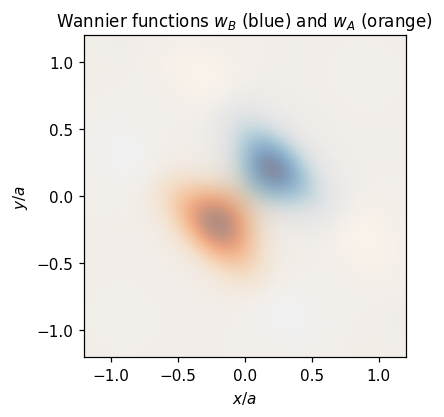

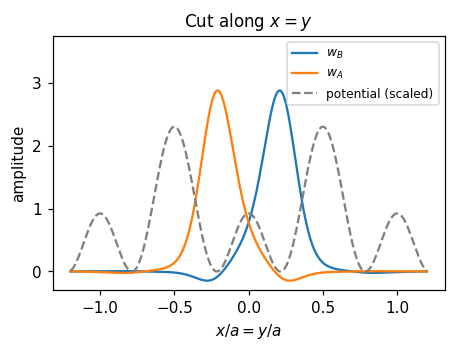

In [7]:
from scipy.interpolate import RegularGridInterpolator

Xw, Yw, (wB, wA) = wannier.compute_wannier_fast(result)   # indexing='ij': first axis is x
interp = lambda w: RegularGridInterpolator((Xw[:, 0], Yw[0, :]), w, method="cubic")

x = y = np.linspace(-1.2, 1.2, 241)
X, Y = np.meshgrid(x, y)
V = potential.potential(X, Y)
w_grid = {name: interp(w)((X, Y)) for name, w in (("B", wB), ("A", wA))}
lim = max(np.abs(w).max() for w in w_grid.values())

fig, ax = plt.subplots(figsize=(4.2, 3.8))
extent = (x.min(), x.max(), y.min(), y.max())
ax.imshow(w_grid["B"], origin="lower", cmap="Blues", extent=extent)
ax.imshow(w_grid["A"], origin="lower", cmap="Oranges", alpha=0.5, extent=extent)
ax.set(xlabel="$x/a$", ylabel="$y/a$", title="Wannier functions $w_B$ (blue) and $w_A$ (orange)")
plt.show()

# Cut along the diagonal x = y, through both wells
fig, ax = plt.subplots(figsize=(4.6, 3.0))
for name in ("B", "A"):
    ax.plot(x, np.diag(w_grid[name]), label=f"$w_{name}$")
v = np.diag(V)
ax.plot(x, 0.8 * lim * (v - v.min()) / (v.max() - v.min()), "--", color="grey", label="potential (scaled)")
ax.set(xlabel="$x/a = y/a$", ylabel="amplitude", title="Cut along $x = y$", ylim=(None, 1.3 * lim))
ax.legend(fontsize=8, loc="upper right")
plt.show()

## 5. Tight-binding model and Hubbard $U$

`result.hamiltonian[(R, m, n)]` $= \langle w_m(0)|H|w_n(R)\rangle$ is the tight-binding Hamiltonian in $E_r$, with $R$ the lattice vector (in units of $a$) and $m, n$ the Wannier indices (1 = B, 2 = A).
The hopping amplitudes are $t = -H$. The largest ones:

In [8]:
H = result.hamiltonian
names = {1: "B", 2: "A"}
# each bond once: B-A for every R, and same-site bonds for R > 0
hoppings = sorted(((R, m, n, -val) for (R, m, n), val in H.items() if m < n or (m == n and R > (0, 0))),
                  key=lambda h: -abs(h[3]))
print(" R         bond     t / E_r")
for R, m, n, t in hoppings[:6]:
    print(f" {str(R):9s} {names[m]}-{names[n]}    {t:+.5f}")

U = wannier.hubbard_U(result)
print(f"\nHubbard U (per sqrt(w_z), see Config.w_z): U_B = {U[0]:.4f}, U_A = {U[1]:.4f} E_r")

 R         bond     t / E_r
 (0, 0)    B-A    +0.31254
 (0, 1)    B-A    +0.27794
 (1, 0)    B-A    +0.27794
 (1, -1)   B-B    -0.04007
 (1, -1)   A-A    -0.04007
 (1, 1)    B-A    +0.03020

Hubbard U (per sqrt(w_z), see Config.w_z): U_B = 0.0585, U_A = 0.0585 E_r


The three B–A bonds are $t_1$ (within the unit cell), $t_2$ (to the neighbouring cells along $x$ and $y$) and $t_3$ (along the diagonal).
The tight-binding bands $H_{mn}(\mathbf q) = \sum_R H_{mn}(R)\, e^{i\mathbf q\cdot R}$ with all hoppings reproduce the two lowest bands of the full calculation.
The nearest-neighbour model with only $t_1$ and $t_2$, $E_\pm(\mathbf q) = \varepsilon \pm |t_1 + t_2(e^{iq_xa} + e^{iq_ya})|$, the brick-wall version of graphene, captures their shape and the Dirac point; the remaining difference comes from $t_3$ and the hopping between equal sites:

t1 = 0.3125, t2 = 0.2779, t3 = 0.0302 E_r


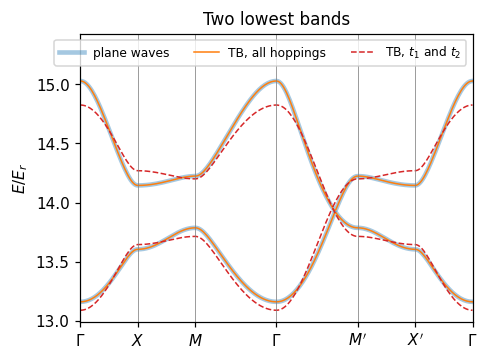

max deviation from the plane-wave bands: all hoppings 1.2e-05 E_r, t1 and t2 only 2.0e-01 E_r


In [9]:
def tb_bands(q):
    Hq = np.zeros((2, 2), dtype=complex)
    for (R, m, n), val in H.items():
        Hq[m - 1, n - 1] += val * np.exp(1j * config.a * (q[0] * R[0] + q[1] * R[1]))
    return np.linalg.eigvalsh(Hq)

t1, t2, t3 = -H[((0, 0), 1, 2)], -H[((1, 0), 1, 2)], -H[((1, 1), 1, 2)]
eps = H[((0, 0), 1, 1)]
print(f"t1 = {t1:.4f}, t2 = {t2:.4f}, t3 = {t3:.4f} E_r")

def nn_bands(q):
    f = abs(t1 + t2 * (np.exp(1j * q[0] * config.a) + np.exp(1j * q[1] * config.a)))
    return np.array([eps - f, eps + f])

tb = np.array([tb_bands(q) for q in qs])
nn = np.array([nn_bands(q) for q in qs])

fig, ax = plt.subplots(figsize=(4.6, 3.4))
lines = [ax.plot(dist, bands[:, :2], color="C0", lw=3, alpha=0.4)[0],
         ax.plot(dist, tb, color="C1", lw=1)[0],
         ax.plot(dist, nn, "--", color="C3", lw=1)[0]]
ax.set_xticks(ticks, path_labels)
for t in ticks[1:-1]:
    ax.axvline(t, color="grey", lw=0.5)
ax.legend(lines, ["plane waves", "TB, all hoppings", "TB, $t_1$ and $t_2$"], fontsize=8, loc="upper right", ncols=3)
ax.set(xlim=(0, ticks[-1]), ylim=(None, max(tb.max(), nn.max()) + 0.4), ylabel=r"$E/E_r$", title="Two lowest bands")
plt.show()
print(f"max deviation from the plane-wave bands: all hoppings {np.abs(tb - bands[:, :2]).max():.1e} E_r, "
      f"t1 and t2 only {np.abs(nn - bands[:, :2]).max():.1e} E_r")

## 6. Other geometries

The same code covers the other lattices of the setup. With $\phi = 0$ the lattice is triangular, with a single well per unit cell at the origin and one band:

In [10]:
tri = Config(V1=10, V2=10, phi=0.0, num_wannier=1)
tri_wannier = Wannier(tri, [(0.0, 0.0)])
tri_result = tri_wannier.wannierize()

hops = sorted(((R, -v) for (R, m, n), v in tri_result.hamiltonian.items() if R > (0, 0)), key=lambda h: -abs(h[1]))
print(" R         t / E_r")
for R, t in hops[:4]:
    print(f" {str(R):9s} {t:+.5f}")
print(f"\nHubbard U (per sqrt(w_z)): {tri_wannier.hubbard_U(tri_result)[0]:.4f} E_r")

 R         t / E_r
 (0, 1)    +0.00752
 (1, 0)    +0.00752
 (1, -1)   +0.00105
 (1, 1)    +0.00013

Hubbard U (per sqrt(w_z)): 0.0783 E_r


## 7. Time evolution: preparing a double-well superposition

The lattice can also be changed in time.
Here we start with an atom in the single well of the square lattice $L_2$ alone ($V_1 = 0$, one Wannier function $w_0$ at the origin) and ramp $V_1$ up linearly, which splits each well into a double well.
The goal is the symmetric superposition $|+\rangle = (|w_B\rangle + |w_A\rangle)/\sqrt 2$ of the final lattice, and the fidelity $F = |\langle +|\psi(T)\rangle|^2$ depends on the ramp time $T$.

- `Wavefunction.from_wannier(result, amplitudes)` builds a superposition of Wannier functions.
- `LinearRamp(start, end, duration)` ramps $V_1$, $V_2$ and $\phi$ linearly; for other protocols, subclass `Ramp` and implement `config_at(t)`.
- `Evolution(ramp).run(psi0, dt)` evolves the state; `result.final` is the state at the end of the ramp.

States are stored k-resolved on the Wannier90 grid, i.e. on a torus of `num_q` $\times$ `num_q` unit cells, so we use a smaller grid and cutoff here.

In [11]:
from optical_lattices import Wavefunction, LinearRamp, Evolution

start = Config(V1=0, V2=16, phi=np.pi, num_wannier=1, num_q=12, L_max=8)
end = Config(V1=20, V2=16, phi=np.pi, num_wannier=2, num_q=12, L_max=8)

r_end = end.V1 / end.V2
p_end = np.arccos(1 / (4 * r_end - 1)) / (2 * end.k)
wells_end = {"B": (p_end, p_end), "A": (-p_end, -p_end)}

w0 = Wavefunction.from_wannier(Wannier(start, [(0.0, 0.0)]).wannierize(), [1])
plus = Wavefunction.from_wannier(Wannier(end, [(0.2, 0.2), (-0.2, -0.2)]).wannierize(), np.array([1, 1]) / np.sqrt(2))

ramp_times = {"fast": 0.1, "moderate": 1.0, "slow": 10.0}
final = {}
for label, T in ramp_times.items():
    result = Evolution(LinearRamp(start, end, duration=T)).run(w0, dt=min(T / 200, 0.05))
    final[label] = result.final
    print(f"{label:9s} T = {T:5.1f}:  F = {final[label].fidelity(plus):.3f}")
print(f"no ramp (sudden quench):  F = {w0.fidelity(plus):.3f}")

fast      T =   0.1:  F = 0.523


moderate  T =   1.0:  F = 0.957


slow      T =  10.0:  F = 0.366
no ramp (sudden quench):  F = 0.504


To look at the states in real space, we evaluate $\psi(\mathbf r) = \sum_{\mathbf k, \mathbf G} c_{\mathbf k \mathbf G}\, e^{i(\mathbf k + \mathbf G)\cdot\mathbf r} / \sqrt{N_k a^2}$, normalized on the torus:

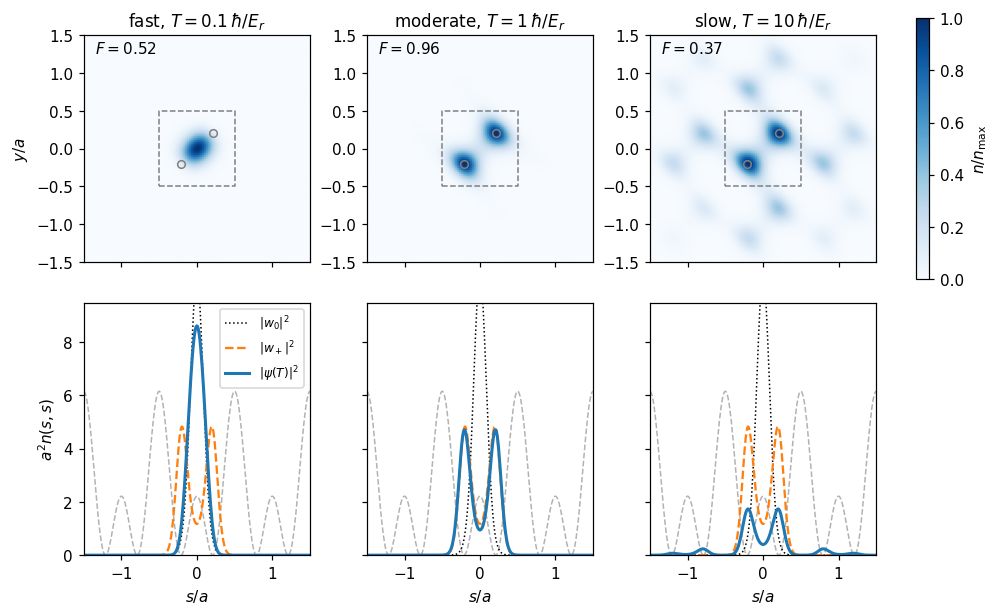

In [12]:
def density(psi, x, y):
    n = np.arange(-psi.L_max, psi.L_max + 1)
    nx, ny = (g.ravel() for g in np.meshgrid(n, n, indexing="xy"))   # plane-wave order of Energy
    k = start.k
    plane_waves = np.exp(2j * k * (np.multiply.outer(nx, x) + np.multiply.outer(ny, y)))
    bloch = np.exp(1j * (np.multiply.outer(psi.k_points[:, 0], x) + np.multiply.outer(psi.k_points[:, 1], y)))
    amplitude = np.sum(bloch * np.tensordot(psi.coefficients, plane_waves, axes=1), axis=0)
    return np.abs(amplitude) ** 2 / len(psi.k_points)

x = y = np.linspace(-1.5, 1.5, 121)
X, Y = np.meshgrid(x, y)
s = np.linspace(-1.5, 1.5, 301)                                     # cut along x = y
cut = {name: density(psi, s, s) for name, psi in [("w0", w0), ("plus", plus)] + list(final.items())}
v_end = Potential(end).potential(s, s)

top = 1.1 * max(cut["plus"].max(), *(cut[label].max() for label in ramp_times))

fig, axes = plt.subplots(2, 3, figsize=(9, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]}, layout="constrained")
for col, (label, T) in enumerate(ramp_times.items()):
    n = density(final[label], X, Y)
    ax = axes[0, col]
    im = ax.imshow(n / n.max(), origin="lower", extent=(x[0], x[-1], y[0], y[-1]), cmap="Blues", vmin=0, vmax=1)
    ax.plot([-0.5, 0.5, 0.5, -0.5, -0.5], [-0.5, -0.5, 0.5, 0.5, -0.5], "--", color="grey", lw=1)
    for wx, wy in wells_end.values():
        ax.plot(wx, wy, "o", mfc="none", color="grey", ms=5)
    ax.text(0.05, 0.92, f"$F = {final[label].fidelity(plus):.2f}$", transform=ax.transAxes)
    ax.set(title=f"{label}, $T = {T:g}\\,\\hbar/E_r$", aspect="equal")

    ax = axes[1, col]
    ax.plot(s, 0.65 * top * (v_end - v_end.min()) / (v_end.max() - v_end.min()), "--", color="grey", alpha=0.6, lw=1)
    ax.plot(s, cut["w0"], ":", color="k", lw=1, label=r"$|w_0|^2$")
    ax.plot(s, cut["plus"], "--", color="C1", label=r"$|w_+|^2$")
    ax.plot(s, cut[label], color="C0", lw=2, label=r"$|\psi(T)|^2$")
    ax.set(xlabel="$s/a$", ylim=(0, top))
    if col > 0:
        ax.tick_params(labelleft=False)
axes[0, 0].set_ylabel("$y/a$")
axes[1, 0].set_ylabel("$a^2 n(s, s)$")
axes[1, 0].legend(fontsize=8)
fig.colorbar(im, ax=axes[0, :], label=r"$n/n_\max$", shrink=0.9)
plt.show()